# CLIMADA

## Hazard

1 events, 71200 centroids


<GeoAxes: title={'center': 'RF max intensity at each point'}>

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


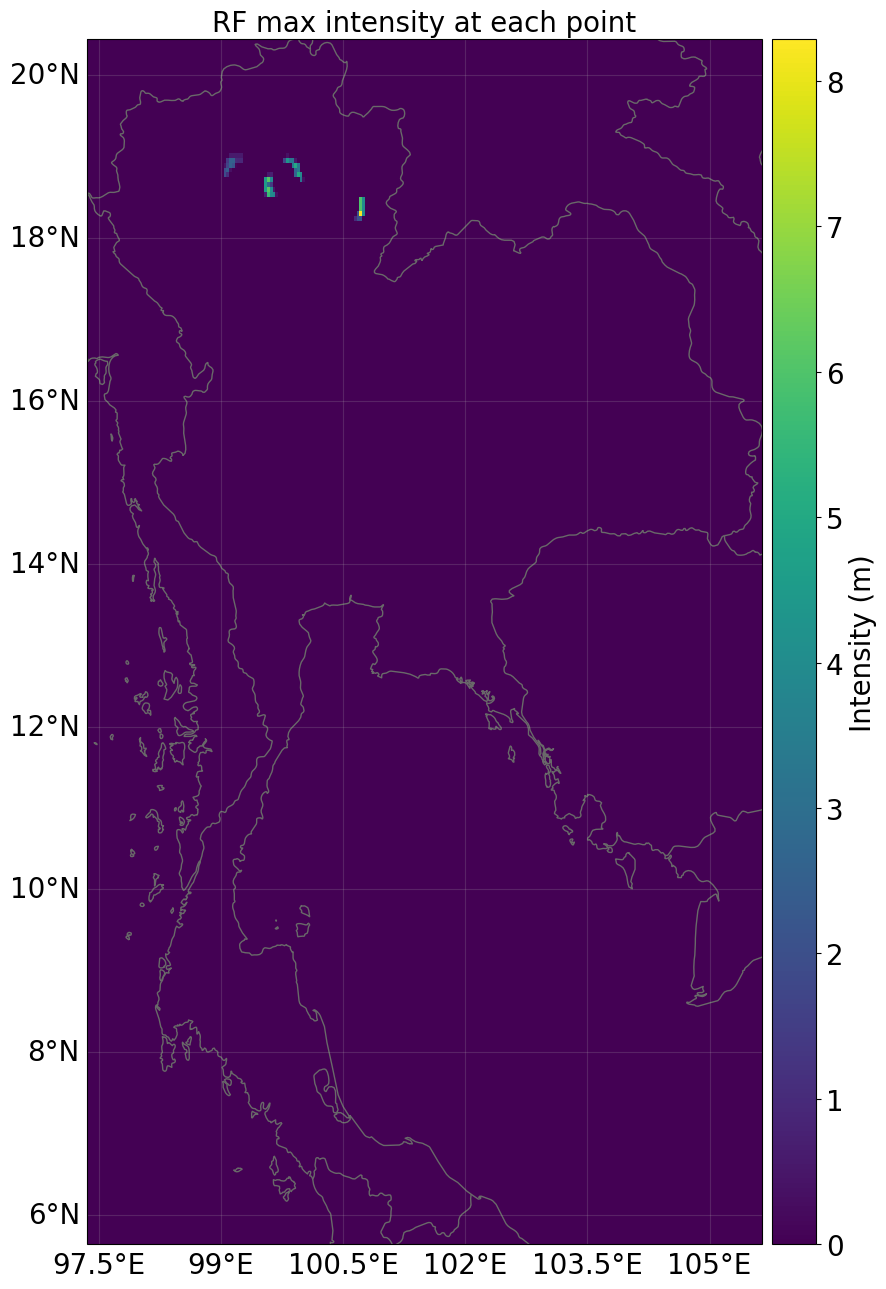

In [81]:
from climada_petals.hazard.river_flood import RiverFlood

# Load river flood hazard from the ISIMIP flood depth (flddph) and flooded fraction (fldfrc) files
rf = RiverFlood.from_isimip_nc(
    dph_path='flddph.nc4',
    frc_path='fldfrc.nc4',
    countries=['THA'],          # ISO3 country code(s) to cut out of the global grid
    years=[2005],   # subset of years (data covers 1971-2010)
)
rf.check()
print(rf.size, 'events,', rf.centroids.size, 'centroids')
rf.plot_intensity(event=0)

<GeoAxes: title={'center': 'RF max intensity at each point'}>

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


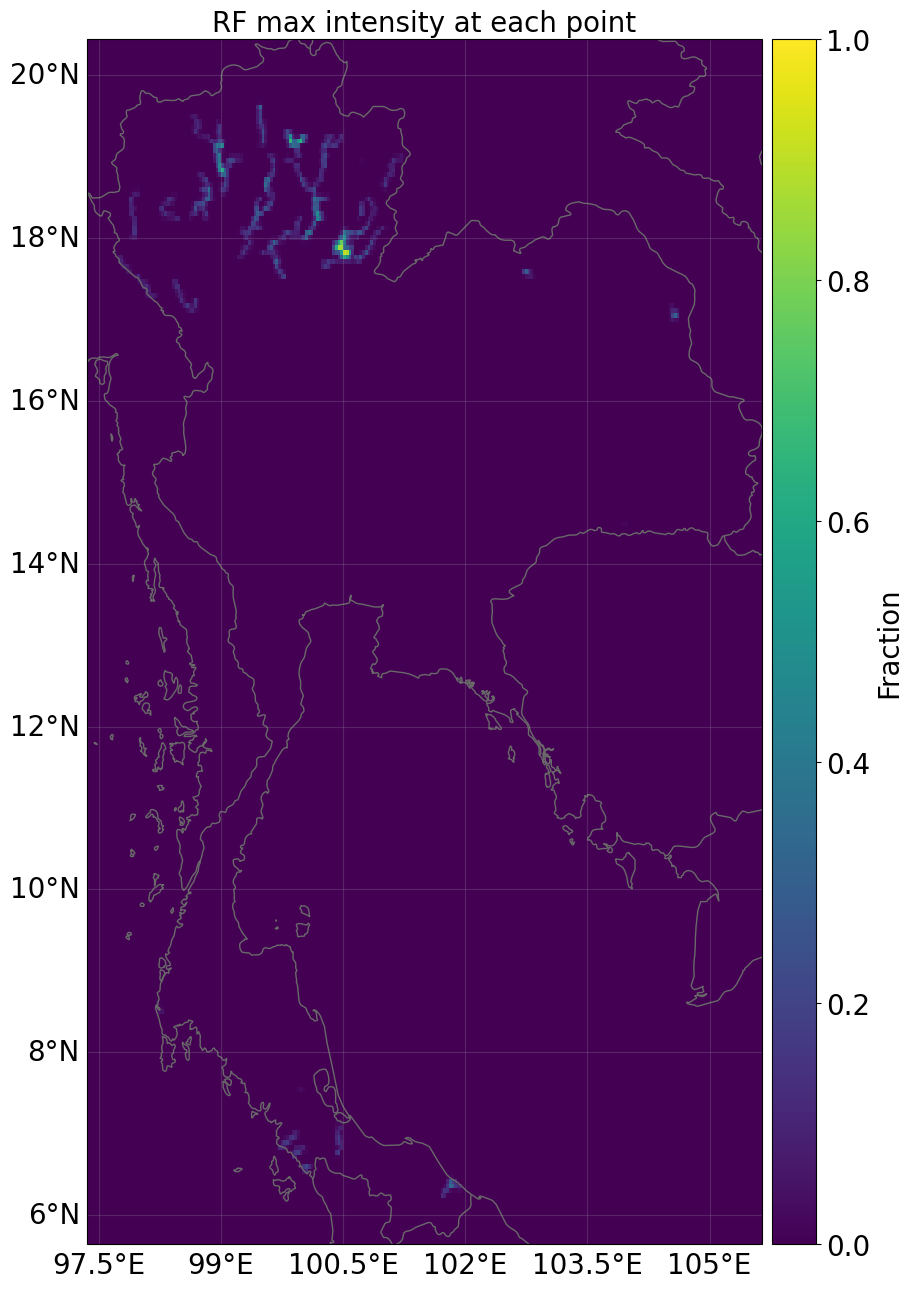

In [34]:
rf.plot_fraction(event=0)

## Exposure
### GDP

In [38]:
import numpy as np
from climada.entity import Exposures
import xarray as xr

gdp2005 = xr.open_dataset('gdp_2005.nc4', use_cftime=True)

/var/folders/hn/pyg79cw15ql332wmddc7h_6c0000gn/T/ipykernel_8190/3599767993.py:4: DeprecationWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  gdp2005 = xr.open_dataset('gdp_2005.nc4', use_cftime=True)


In [42]:
gdp_map = gdp2005['gdp'].isel(time=0) 
gdp_tha = gdp_map.sel(lat=slice(21, 4), lon=slice(96, 107))
lon2d, lat2d = np.meshgrid(gdp_tha.lon.values, gdp_tha.lat.values)
exp = Exposures(
    lat=lat2d.ravel(), 
    lon=lon2d.ravel(), 
    value=gdp_tha.values.ravel())
print(exp.gdf)

                geometry         value
0    POINT (96.25 20.75)  3.713880e+08
1    POINT (96.75 20.75)  3.623080e+08
2    POINT (97.25 20.75)  3.110018e+08
3    POINT (97.75 20.75)  1.527207e+08
4    POINT (98.25 20.75)  5.991712e+07
..                   ...           ...
743  POINT (104.75 4.25)  0.000000e+00
744  POINT (105.25 4.25)  0.000000e+00
745  POINT (105.75 4.25)  0.000000e+00
746  POINT (106.25 4.25)  0.000000e+00
747  POINT (106.75 4.25)  0.000000e+00

[748 rows x 2 columns]


<GeoAxes: >

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


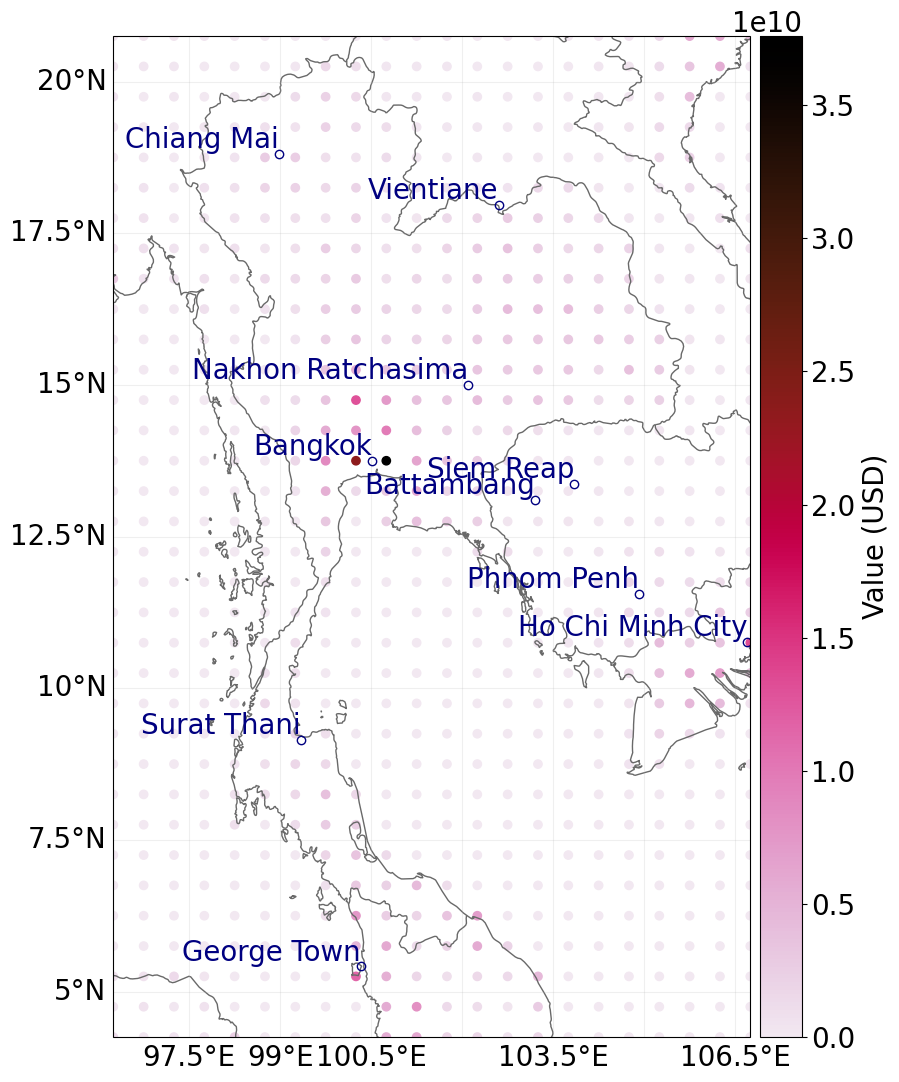

In [45]:
exp.plot_scatter()

In [48]:
import pandas as pd
from climada_petals.entity.exposures.gdp_asset import GDP2Asset

# DEMO_GDP2ASSET is a demo file that only covers Switzerland (CHE) -> "Asset Data does not match selected country".
# GDP2Asset needs a GDP file that:
#   - has a variable called 'gdp_grid' with dims (time, lat, lon)
#   - has the year given as ref_year on its time axis
#   - covers the whole country
# so we convert our own gdp_2005.nc4 into that format.

# 1) one time step (keep the time dimension with [0]), box a bit larger than Thailand, lat ascending
gdp_box = gdp2005['gdp'].isel(time=[0]).sel(lat=slice(22, 3), lon=slice(95, 108)).sortby('lat')

# 2) GDP2Asset samples the GDP grid at 2.5 arcmin points (nearest neighbour).
#    One 0.5 deg cell contains 12 x 12 = 144 of those points, so split each cell's GDP evenly
#    (otherwise every cell's GDP would be counted 144 times)
gdp_box = gdp_box / 144

# 3) label the time step as 2005 and save with the variable name GDP2Asset expects
gdp_box = gdp_box.assign_coords(time=[pd.Timestamp('2005-01-01')])
gdp_box.encoding = {}   # drop the original file's storage settings
gdp_box.to_dataset(name='gdp_grid').to_netcdf('gdp_2005_THA_gdp2asset.nc')

# 4) build the asset exposure from the converted file
gdp_isimip = GDP2Asset()
gdp_isimip.set_countries(countries=['THA'], ref_year=2005, path='gdp_2005_THA_gdp2asset.nc')
print(f"total asset value: {gdp_isimip.gdf['value'].sum():,.0f}")
gdp_isimip.gdf

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/climada/util/coordinates.py:991: RuntimeWarning: invalid value encountered in cast
  region_id = hdf5_f["NatIdGrid"].reshape(grid_shape).astype(int)


total asset value: 349,964,824,870


,impf_RF,region_id,value,geometry
0,2.0,7.0,7.642440e+06,POINT (101.14555 5.64565)
1,2.0,7.0,7.642440e+06,POINT (101.10388 5.68731)
2,2.0,7.0,7.642440e+06,POINT (101.14555 5.68731)
3,2.0,7.0,7.642440e+06,POINT (101.18722 5.68731)
4,2.0,7.0,7.642440e+06,POINT (101.22888 5.68731)
...,...,...,...,...
25563,2.0,7.0,8.322447e+06,POINT (99.97889 20.39562)
25564,2.0,7.0,5.505639e+06,POINT (100.02055 20.39562)
25565,2.0,7.0,8.322447e+06,POINT (99.89555 20.43729)
25566,2.0,7.0,8.322447e+06,POINT (99.93722 20.43729)


<GeoAxes: >

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


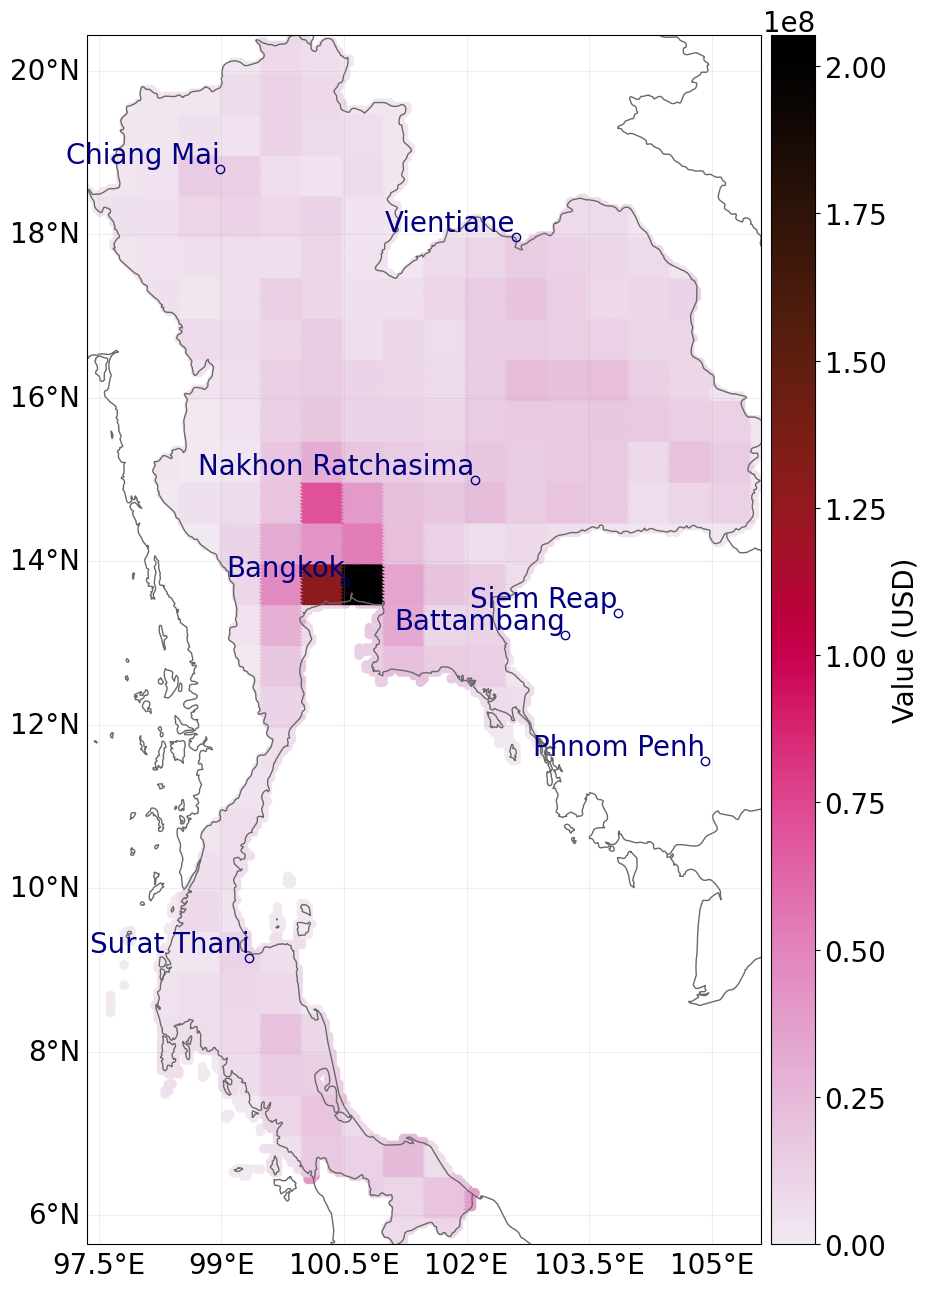

In [49]:
gdp_isimip.plot_scatter()

### Crop

variable: aet-ric-firr | units: mm yr-1
25568 crop points | 25568 GDP points
                         geometry       value  region_id
0       POINT (101.14555 5.64565)  540.010742        7.0
1       POINT (101.10388 5.68731)  540.010742        7.0
2       POINT (101.14555 5.68731)  540.010742        7.0
3       POINT (101.18722 5.68731)  540.010742        7.0
4       POINT (101.22888 5.68731)  540.010742        7.0
...                           ...         ...        ...
25563   POINT (99.97889 20.39562)  338.532898        7.0
25564  POINT (100.02055 20.39562)  338.532898        7.0
25565   POINT (99.89555 20.43729)  338.532898        7.0
25566   POINT (99.93722 20.43729)  338.532898        7.0
25567   POINT (99.97889 20.43729)  338.532898        7.0

[25568 rows x 3 columns]


<GeoAxes: >

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


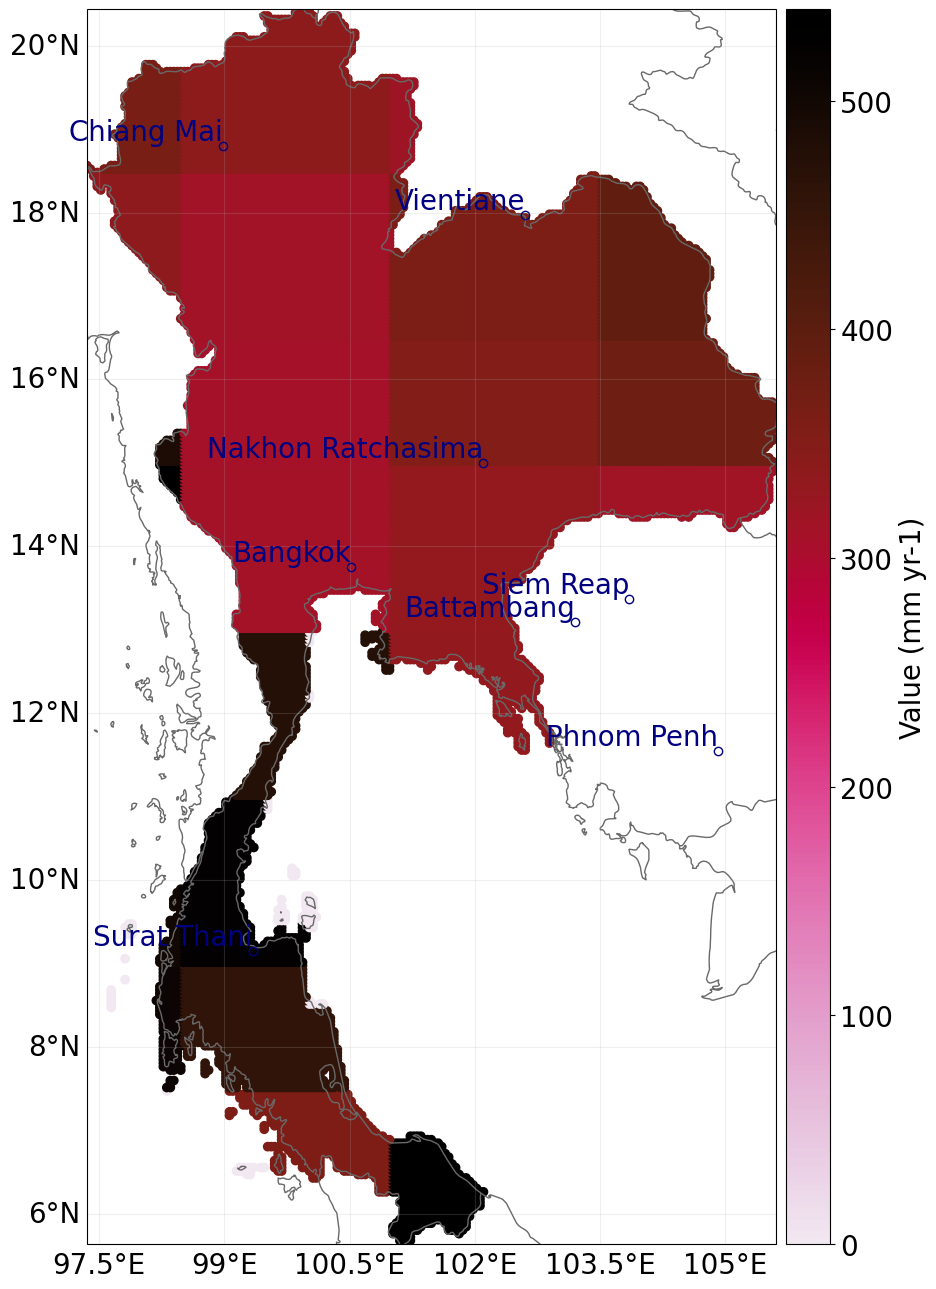

In [78]:
# CropProduction.from_isimip_netcdf() needs the ISIMIP *landuse* file (e.g. 'histsoc_landuse-15crops_annual_1861_2005.nc'),
# so we build the exposure directly from a crop-model file instead.
# NOTE: 'aet-ric-firr' = actual evapotranspiration of irrigated rice, NOT yield.
#       For yield use: clm-crop_watch-wfdei_nobc_hist_co2_yield-ric-firr-default_global_annual_1980_2012.nc4
crop_file = 'clm-crop_watch-wfdei_nobc_hist_co2_aet-ric-firr-default_global_annual_1980_2012.nc4'

crop_ds = xr.open_dataset(crop_file, decode_times=False)   # time is "growing seasons since 1980"
crop_var = [v for v in crop_ds.data_vars if {'lat', 'lon'} <= set(crop_ds[v].dims)][0]
print('variable:', crop_var, '| units:', crop_ds[crop_var].attrs.get('units'))

# mean over all years (0.5 deg grid)
crop_mean = crop_ds[crop_var].mean(dim='time')

# use the SAME points as the GDP exposure (gdp_isimip: 2.5 arcmin points inside Thailand)
pts_lat = gdp_isimip.gdf.geometry.y.values
pts_lon = gdp_isimip.gdf.geometry.x.values

# each 2.5 arcmin point takes the value of the 0.5 deg cell it lies in (nearest neighbour),
# same as GDP2Asset does for GDP.
# No division by 144 here: yield / evapotranspiration are per-area values (t/ha, kg/m2),
# not totals per cell like GDP, so every point in a cell gets the cell's full value.
crop_pts = crop_mean.sel(
    lat=xr.DataArray(pts_lat, dims='points'),
    lon=xr.DataArray(pts_lon, dims='points'),
    method='nearest',
).values
crop_pts = np.nan_to_num(crop_pts)      # cells with no rice -> 0

exp_crop = Exposures(
    lat=pts_lat,
    lon=pts_lon,
    value=crop_pts,
    value_unit=crop_ds[crop_var].attrs.get('units', ''),
)
exp_crop.gdf['region_id'] = gdp_isimip.gdf['region_id'].values
print(len(exp_crop.gdf), 'crop points |', len(gdp_isimip.gdf), 'GDP points')
print(exp_crop.gdf)
exp_crop.plot_scatter()

## Vulnerability

In [70]:
from climada.entity import ImpactFuncSet, ImpactFunc
from climada.engine import ImpactCalc
from climada_petals.entity.impact_funcs.river_flood import ImpfRiverFlood, flood_imp_func_set

impf_set = flood_imp_func_set()   # residential sector by default
print("impact function ids in the set:", impf_set.get_ids('RF'))

# GDP2Asset assigns the OLD id scheme (2 = Asia), but the impact function set uses
# id = region code + sector code  (Asia = 20, residential = 1  ->  21)
gdp_isimip.gdf['impf_RF'] = 21


impact function ids in the set: [11, 21, 31, 41, 51, 61]


## Impact

In [71]:

imp = ImpactCalc(gdp_isimip, impf_set, rf).impact(
    save_mat = False
)
print(f"expected annual impact: {imp.aai_agg:,.0f} USD")
print(f"max expected annual impact per exposure point: {imp.eai_exp.max():,.0f} USD")
print(f"number of points with impact > 0: {(imp.eai_exp > 0).sum()}")

expected annual impact: 46,568,105 USD
max expected annual impact per exposure point: 3,802,164 USD
number of points with impact > 0: 44


<GeoAxes: title={'center': 'Expected annual impact'}>

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


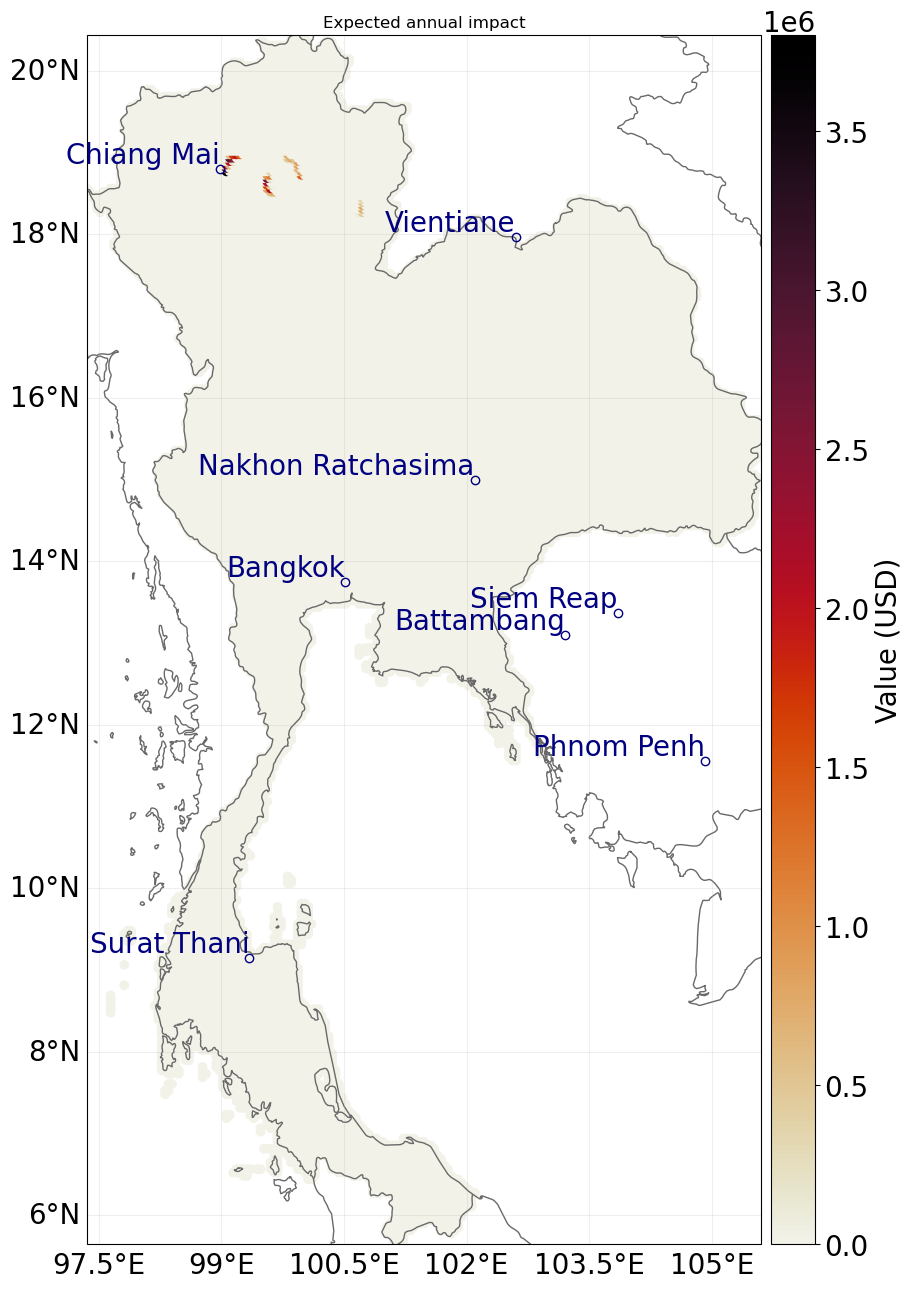

In [59]:
imp.plot_scatter_eai_exposure()

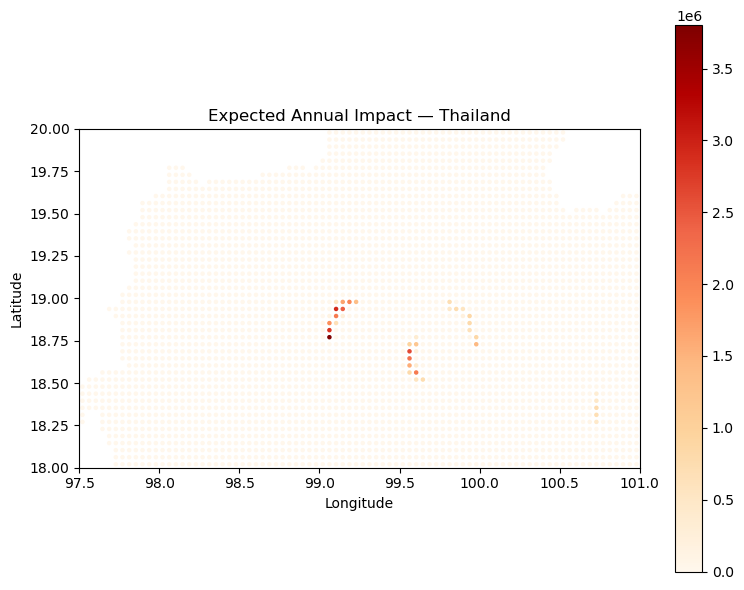

In [68]:
import matplotlib.pyplot as plt

lon_min, lon_max = 97.5, 101
lat_min, lat_max = 18, 20

# use the exposure the impact was calculated with (gdp_isimip, 25568 points), not exp (748 points)
gdp_isimip.gdf['eai'] = imp.eai_exp

thailand = gdp_isimip.gdf.cx[lon_min:lon_max, lat_min:lat_max]

fig, ax = plt.subplots(figsize=(8, 6))   # create the axes to draw on
thailand.plot(
    column='eai',
    cmap='OrRd',
    legend=True,
    markersize=5,
    ax=ax
)
ax.set_xlim(lon_min, lon_max)            # set_... methods belong to ax, not plt
ax.set_ylim(lat_min, lat_max)
ax.set_title('Expected Annual Impact — Thailand')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

return periods (years): [1.]
loss at each return period: [46568104.99169639]
exceedance frequency (1/yr): [1.]


<Axes: title={'center': 'Exceedance frequency curve'}, xlabel='Return period (year)', ylabel='Impact (USD)'>

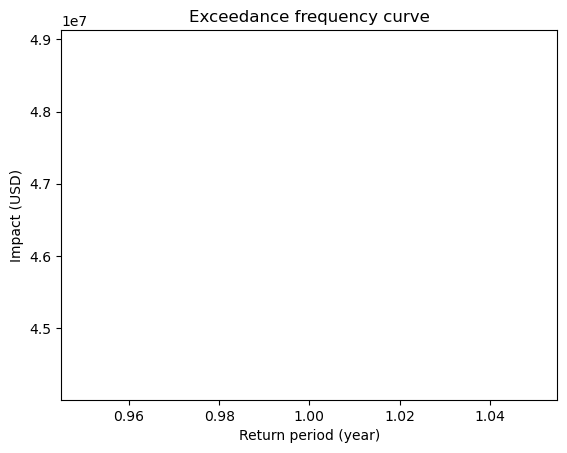

In [84]:
fc = imp.calc_freq_curve()

# ImpactFreqCurve has no .freq attribute -> exceedance frequency = 1 / return period
print('return periods (years):', fc.return_per)
print('loss at each return period:', fc.impact)
print('exceedance frequency (1/yr):', 1 / fc.return_per)
fc.plot()       # built-in plot

crop impact function id: 26
expected annual crop impact: 2,104.71 mm yr-1
number of points with impact > 0: 44


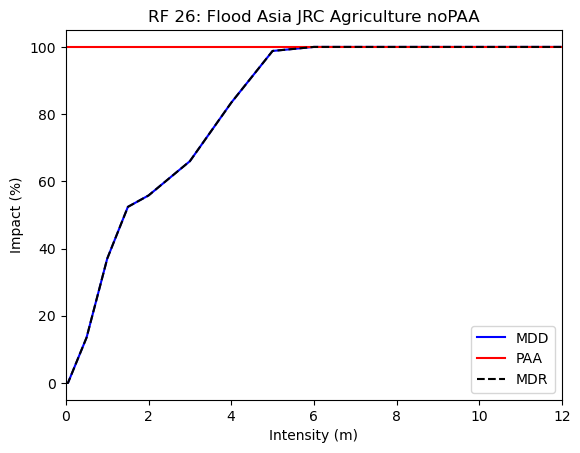

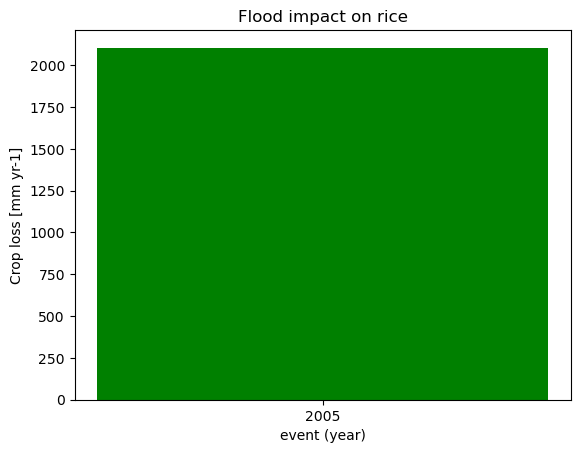

<GeoAxes: title={'center': 'Expected annual impact'}>

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


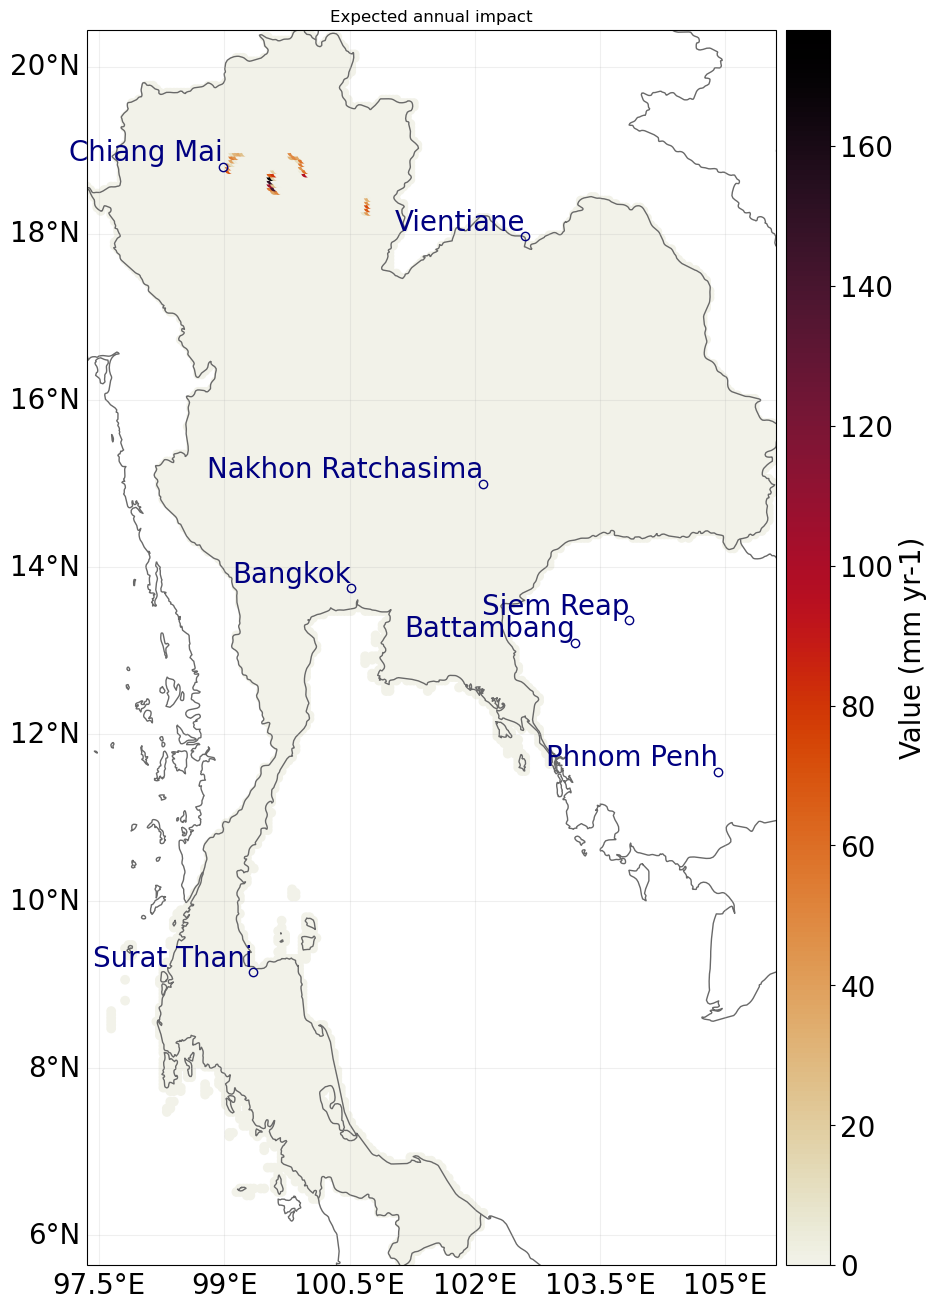

In [83]:
from climada.engine import ImpactCalc
from climada_petals.entity.impact_funcs.river_flood import ImpfRiverFlood

# Flood damage function for AGRICULTURE in Asia (JRC, Huizinga et al. 2017)
# id = region code + sector code  (Asia = 20, agriculture = 6  ->  26)
impf_agri = ImpfRiverFlood.from_jrc_region_sector('Asia', sector='agriculture')
impf_set_crop = ImpactFuncSet([impf_agri])
print('crop impact function id:', impf_agri.id)
impf_agri.plot()

# tell every crop exposure point which impact function to use for river flood (column 'impf_RF')
exp_crop.gdf['impf_RF'] = impf_agri.id

# Impact().calc() is the old API -> use ImpactCalc
imp_crop = ImpactCalc(exp_crop, impf_set_crop, rf).impact(save_mat=False)
print(f"expected annual crop impact: {imp_crop.aai_agg:,.2f} {exp_crop.value_unit}")
print(f"number of points with impact > 0: {(imp_crop.eai_exp > 0).sum()}")

# impact per event (rf has one event per year you loaded)
fig, ax = plt.subplots(facecolor='w')
ax.bar([str(n) for n in rf.event_name], imp_crop.at_event, color='g')
ax.set_title('Flood impact on rice')
ax.set_xlabel('event (year)')
ax.set_ylabel(f'Crop loss [{exp_crop.value_unit}]')   # exp_crop, not exp (that one is GDP)
plt.show()

imp_crop.plot_scatter_eai_exposure()